In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("titanic.csv")
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,0,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,1,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,0,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,0,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,1,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


In [3]:
df.shape

(418, 12)

In [4]:
df.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='str')

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  418 non-null    int64  
 1   Survived     418 non-null    int64  
 2   Pclass       418 non-null    int64  
 3   Name         418 non-null    str    
 4   Sex          418 non-null    str    
 5   Age          332 non-null    float64
 6   SibSp        418 non-null    int64  
 7   Parch        418 non-null    int64  
 8   Ticket       418 non-null    str    
 9   Fare         417 non-null    float64
 10  Cabin        91 non-null     str    
 11  Embarked     418 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 39.3 KB


In [6]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,418.000000,418.000000,418.000000,332.000000,418.000000,418.000000,417.000000
mean,1100.500000,0.363636,2.265550,30.272590,0.447368,0.392344,35.627188
std,120.810458,0.481622,0.841838,14.181209,0.896760,0.981429,55.907576
min,892.000000,0.000000,1.000000,0.170000,0.000000,0.000000,0.000000
25%,996.250000,0.000000,1.000000,21.000000,0.000000,0.000000,7.895800
50%,1100.500000,0.000000,3.000000,27.000000,0.000000,0.000000,14.454200
75%,1204.750000,1.000000,3.000000,39.000000,1.000000,0.000000,31.500000
max,1309.000000,1.000000,3.000000,76.000000,8.000000,9.000000,512.329200


In [7]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age             86
SibSp            0
Parch            0
Ticket           0
Fare             1
Cabin          327
Embarked         0
dtype: int64

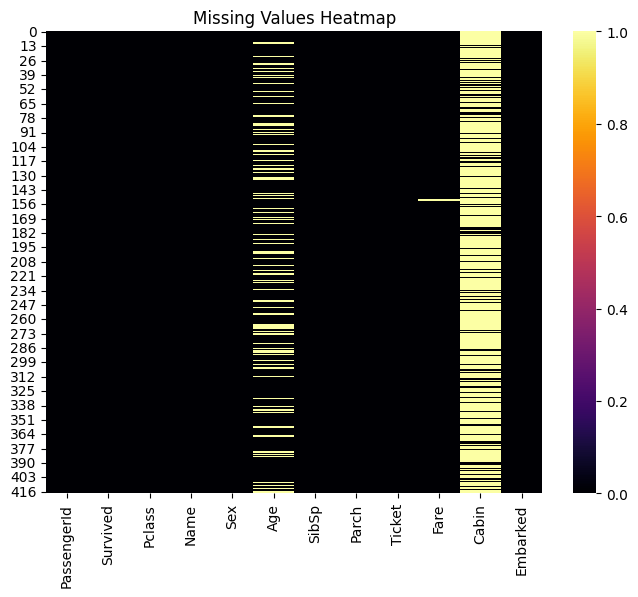

In [8]:
plt.figure(figsize=(8,6))

sns.heatmap(df.isnull(),cmap='inferno')

plt.title("Missing Values Heatmap")
plt.show()

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df["Name"].nunique()

418

In [11]:
df["Age"].nunique()

79

In [12]:
for col in df.columns:
    print(col, ":", df[col].nunique())

PassengerId : 418
Survived : 2
Pclass : 3
Name : 418
Sex : 2
Age : 79
SibSp : 7
Parch : 8
Ticket : 363
Fare : 169
Cabin : 76
Embarked : 3


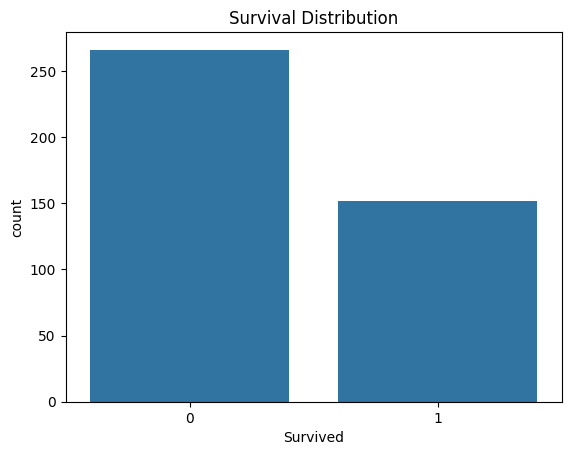

In [ ]:
# plt.figure(figsize=(6,4))
sns.countplot(x='Survived', data=df)
plt.title("Survival Distribution")
# plt.show()

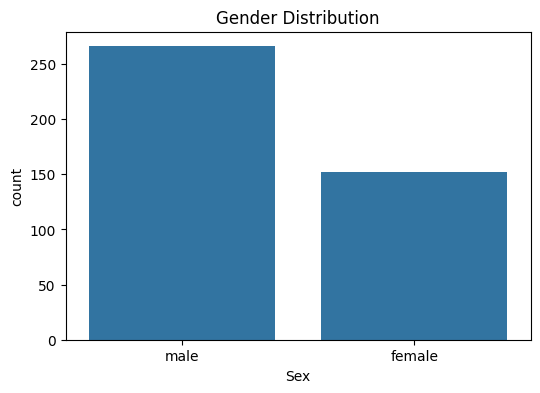

In [14]:
plt.figure(figsize=(6,4))
sns.countplot(x='Sex', data=df)
plt.title("Gender Distribution")
plt.show()

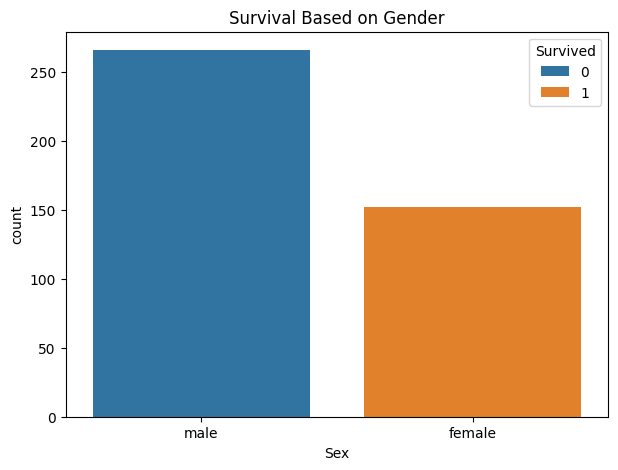

In [15]:
plt.figure(figsize=(7,5))
sns.countplot(x='Sex',hue='Survived',data=df)
plt.title("Survival Based on Gender")
plt.show()

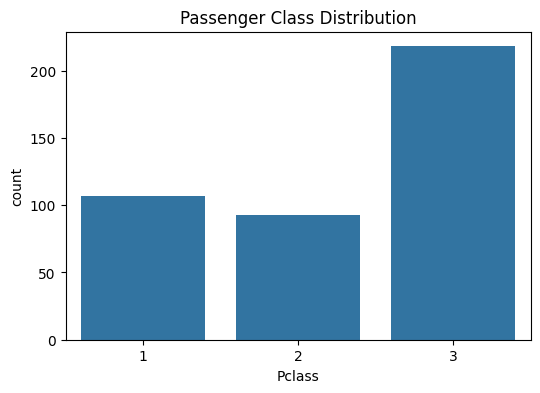

In [16]:
plt.figure(figsize=(6,4))

sns.countplot(x='Pclass', data=df)
plt.title("Passenger Class Distribution")
plt.show()

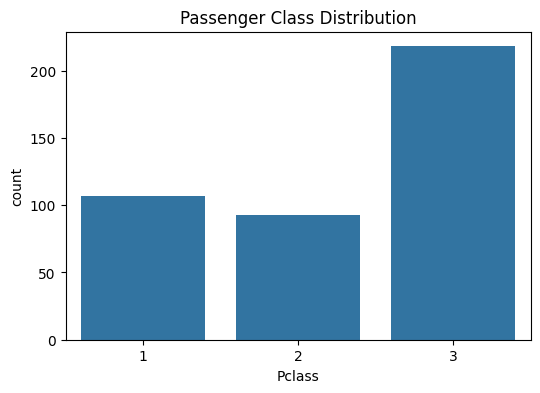

In [17]:
plt.figure(figsize=(6,4))
sns.countplot(x='Pclass', data=df)
plt.title("Passenger Class Distribution")
plt.show()

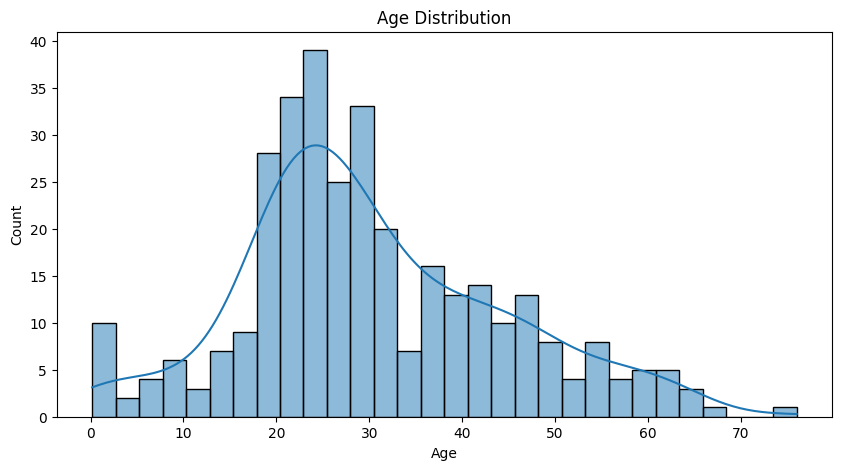

In [18]:
plt.figure(figsize=(10,5))
sns.histplot(df['Age'],bins=30,kde=True)
plt.title("Age Distribution")
plt.show()

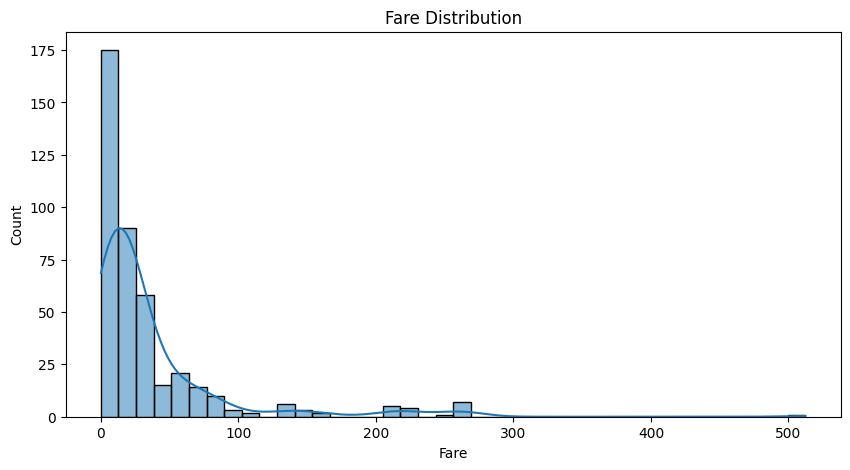

In [19]:
plt.figure(figsize=(10,5))

sns.histplot(df['Fare'],bins=40,kde=True)

plt.title("Fare Distribution")
plt.show()

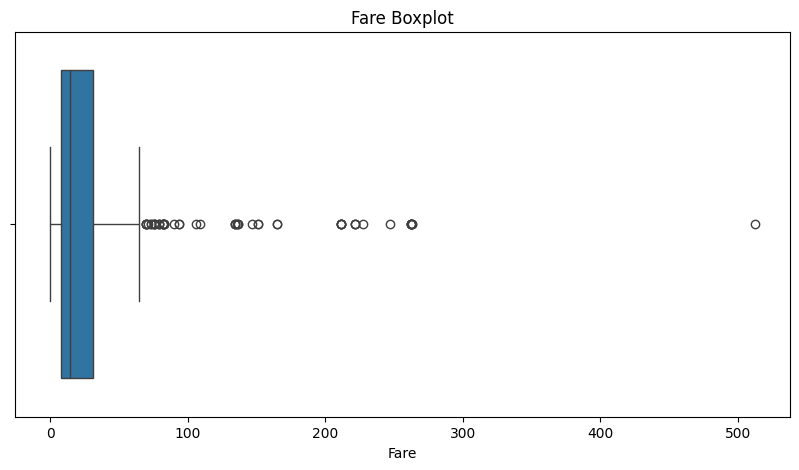

In [20]:
plt.figure(figsize=(10,5))

sns.boxplot(x=df['Fare'])

plt.title("Fare Boxplot")
plt.show()

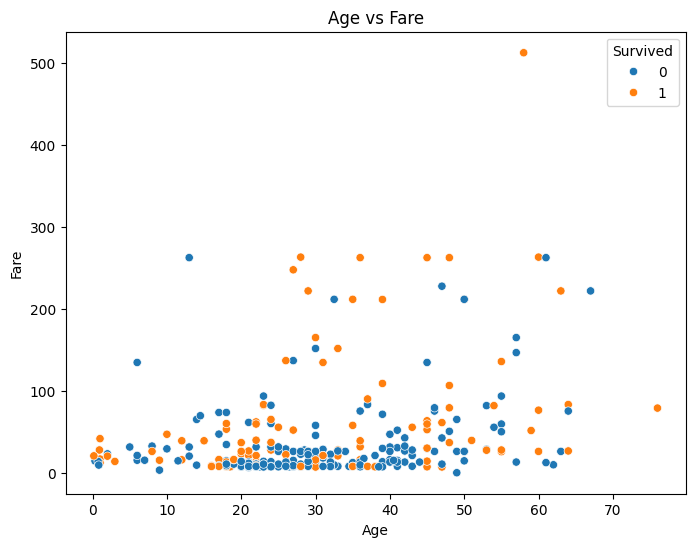

In [21]:
plt.figure(figsize=(8,6))
sns.scatterplot(x='Age',y='Fare',hue='Survived',data=df)
plt.title("Age vs Fare")
plt.show()

In [22]:
numeric_df = df.select_dtypes(include=np.number)
corr = numeric_df.corr()
corr

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
PassengerId,1.000000,-0.023245,-0.026751,-0.034102,0.003818,0.043080,0.008211
Survived,-0.023245,1.000000,-0.108615,-0.000013,0.099943,0.159120,0.191514
Pclass,-0.026751,-0.108615,1.000000,-0.492143,0.001087,0.018721,-0.577147
Age,-0.034102,-0.000013,-0.492143,1.000000,-0.091587,-0.061249,0.337932
SibSp,0.003818,0.099943,0.001087,-0.091587,1.000000,0.306895,0.171539
Parch,0.043080,0.159120,0.018721,-0.061249,0.306895,1.000000,0.230046
Fare,0.008211,0.191514,-0.577147,0.337932,0.171539,0.230046,1.000000


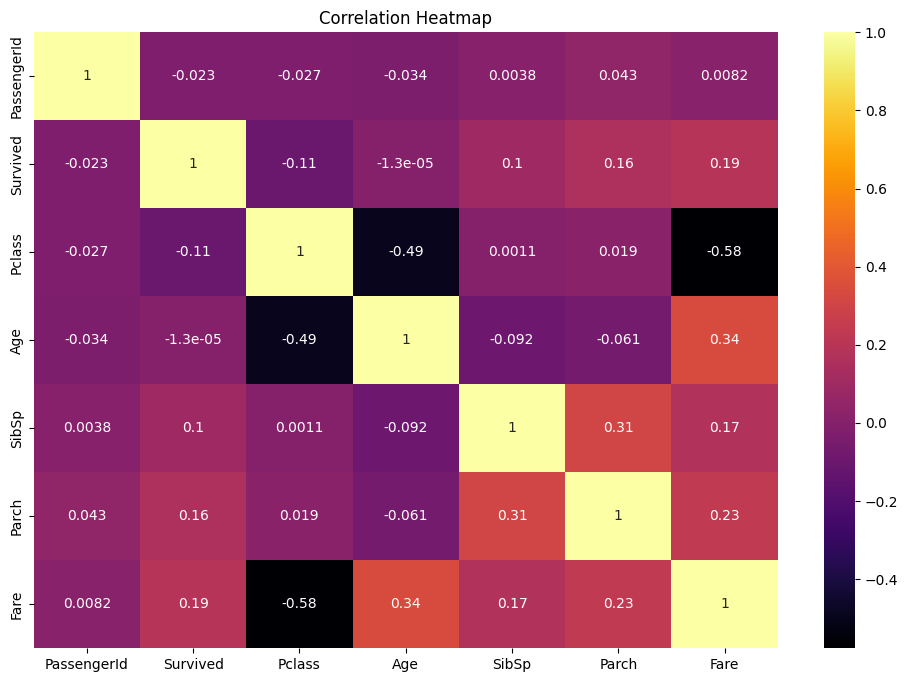

In [23]:
plt.figure(figsize=(12,8))
sns.heatmap(corr,annot=True,cmap='inferno')
plt.title("Correlation Heatmap")
plt.show()

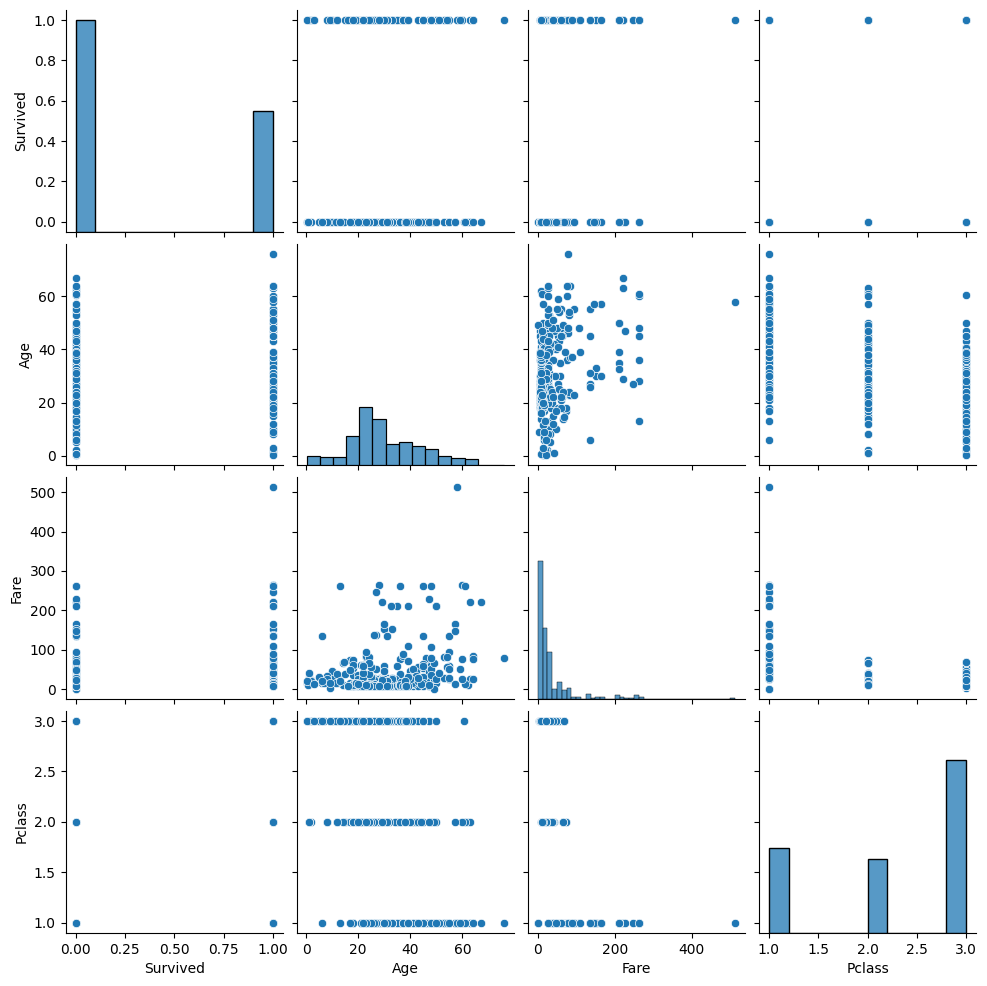

In [24]:
sns.pairplot(df[['Survived','Age','Fare','Pclass']])
plt.show()

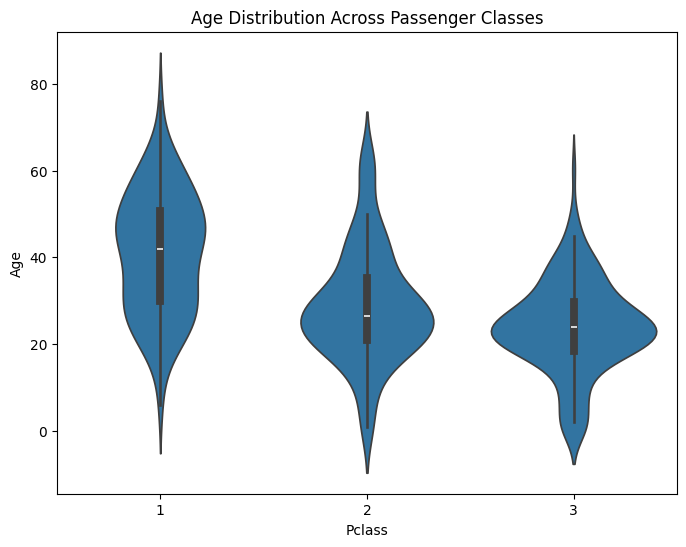

In [25]:
plt.figure(figsize=(8,6))
sns.violinplot(x='Pclass',y='Age',data=df)
plt.title("Age Distribution Across Passenger Classes")
plt.show()

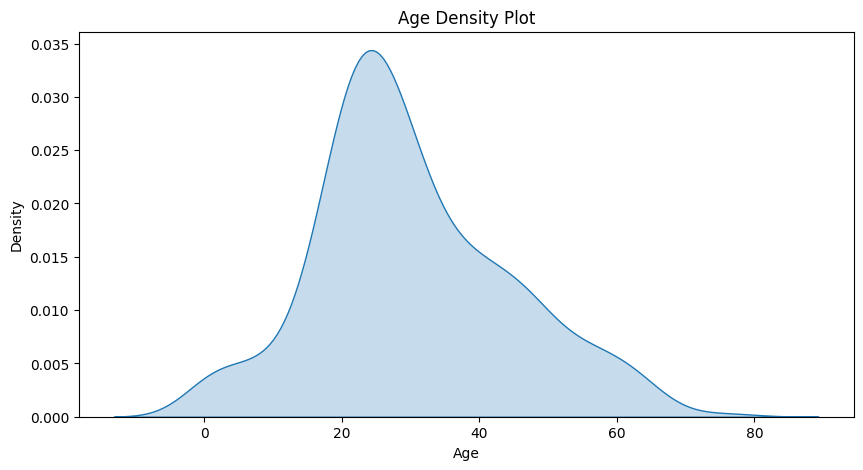

In [26]:
plt.figure(figsize=(10,5))
sns.kdeplot(df['Age'],fill=True)
plt.title("Age Density Plot")
plt.show()

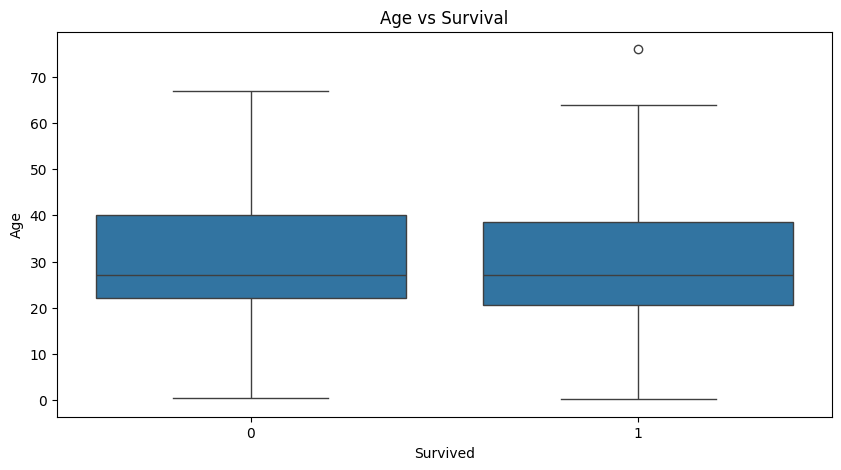

In [27]:
plt.figure(figsize=(10,5))
sns.boxplot(x='Survived',y='Age',data=df)
plt.title("Age vs Survival")
plt.show()

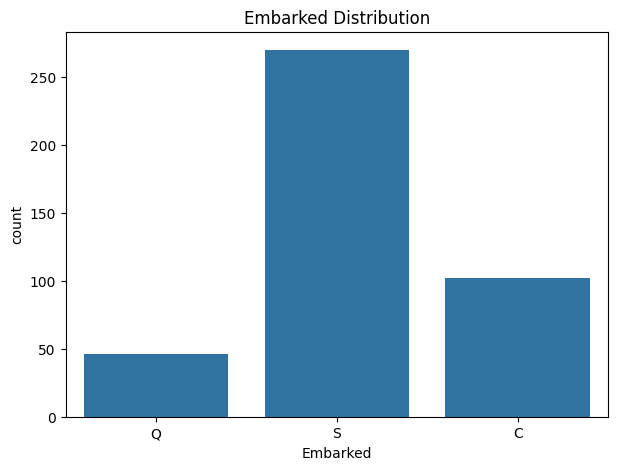

In [28]:
plt.figure(figsize=(7,5))
sns.countplot(x='Embarked',data=df)
plt.title("Embarked Distribution")
plt.show()

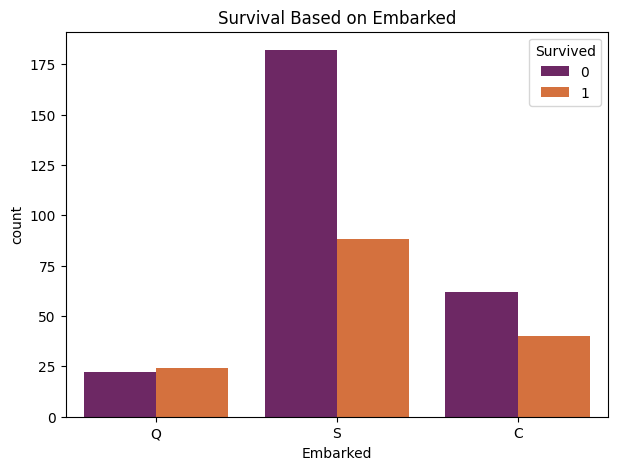

In [29]:
plt.figure(figsize=(7,5))
sns.countplot(x='Embarked',hue='Survived',data=df,palette='inferno')
plt.title("Survival Based on Embarked")
plt.show()

In [30]:
df['FamilySize'] = df['SibSp'] + df['Parch']
df[['SibSp', 'Parch', 'FamilySize']].head()

,SibSp,Parch,FamilySize
0,0,0,0
1,1,0,1
2,0,0,0
3,0,0,0
4,1,1,2


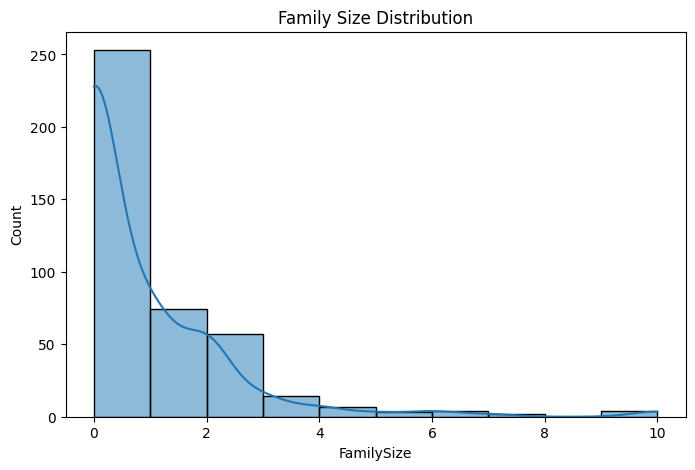

In [31]:
plt.figure(figsize=(8,5))
sns.histplot(df['FamilySize'],bins=10,kde=True)
plt.title("Family Size Distribution")
plt.show()

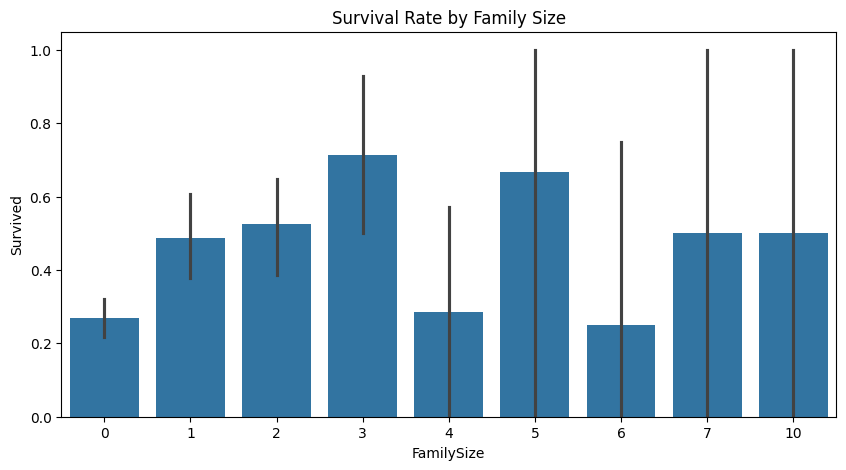

In [32]:
plt.figure(figsize=(10,5))
sns.barplot(x='FamilySize',y='Survived',data=df)
plt.title("Survival Rate by Family Size")
plt.show()

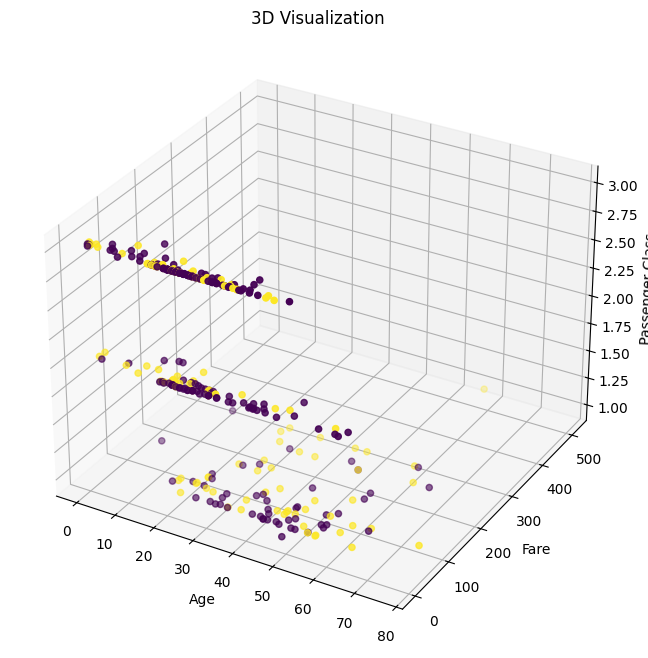

In [33]:
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(10,8))

ax = fig.add_subplot(111, projection='3d')

x = df['Age']
y = df['Fare']
z = df['Pclass']

scatter = ax.scatter(x,y,z,c=df['Survived'],cmap='viridis')

ax.set_xlabel("Age")
ax.set_ylabel("Fare")
ax.set_zlabel("Passenger Class")

plt.title("3D Visualization")
plt.show()

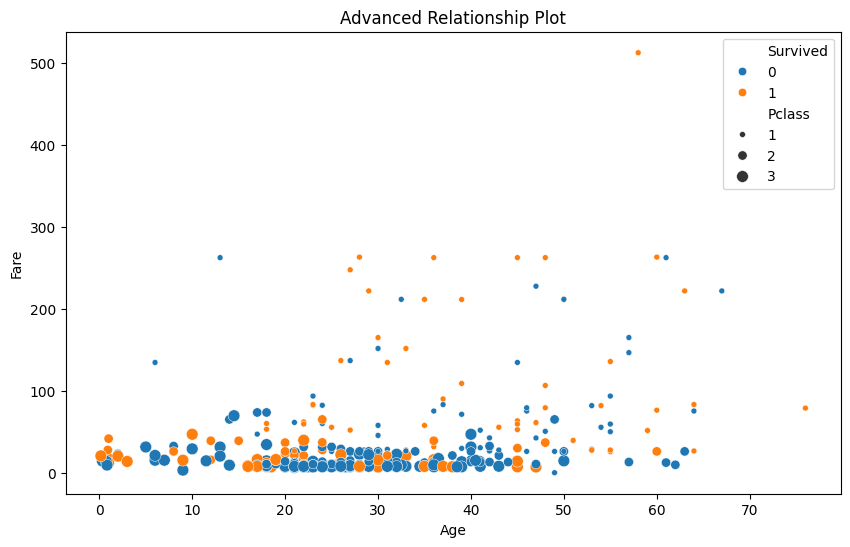

In [34]:
plt.figure(figsize=(10,6))

sns.scatterplot(x='Age',
                y='Fare',
                hue='Survived',
                size='Pclass',
                data=df)

plt.title("Advanced Relationship Plot")
plt.show()

In [35]:
pd.crosstab(df['Sex'],df['Survived'])

Survived,0,1
Sex,,
female,0,152
male,266,0


In [36]:
survival_rate = df['Survived'].value_counts(normalize=True) * 100
survival_rate

Survived
0    63.636364
1    36.363636
Name: proportion, dtype: float64

In [37]:
df[df["Sex"] == "male"]["Survived"].nunique()

1

In [38]:
df[df["Sex"] == "female"]["Survived"].nunique()


1

In [39]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

In [40]:
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,FamilySize
0,892,0,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q,0
1,893,1,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S,1
2,894,0,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q,0
3,895,0,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S,0
4,896,1,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...
413,1305,0,3,"Spector, Mr. Woolf",male,NaN,0,0,A.5. 3236,8.0500,NaN,S,0
414,1306,1,1,"Oliva y Ocana, Dona. Fermina",female,39.0,0,0,PC 17758,108.9000,C105,C,0
415,1307,0,3,"Saether, Mr. Simon Sivertsen",male,38.5,0,0,SOTON/O.Q. 3101262,7.2500,NaN,S,0
416,1308,0,3,"Ware, Mr. Frederick",male,NaN,0,0,359309,8.0500,NaN,S,0


In [41]:
data = df[['Survived',
           'Pclass',
           'Sex',
           'Age',
           'Fare',
           'SibSp',
           'Parch']]

In [42]:
data['Age'].fillna(data['Age'].mean(), inplace=True)
data['Fare'].fillna(data['Fare'].mean(), inplace=True)

C:\Users\Vishesh\AppData\Local\Temp\ipykernel_26780\1949522192.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  data['Age'].fillna(data['Age'].mean(), inplace=True)
C:\Users\Vishesh\AppData\Local\Temp\ipykernel_26780\1949522192.py:2: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained as

0        7.8292
1        7.0000
2        9.6875
3        8.6625
4       12.2875
         ...   
413      8.0500
414    108.9000
415      7.2500
416      8.0500
417     22.3583
Name: Fare, Length: 418, dtype: float64

In [43]:
encoder = LabelEncoder()
data['Sex'] = encoder.fit_transform(data['Sex'])

In [44]:
data.head()

,Survived,Pclass,Sex,Age,Fare,SibSp,Parch
0,0,3,1,34.5,7.8292,0,0
1,1,3,0,47.0,7.0000,1,0
2,0,2,1,62.0,9.6875,0,0
3,0,3,1,27.0,8.6625,0,0
4,1,3,0,22.0,12.2875,1,1


In [45]:
X = data.drop('Survived', axis=1)

y = data['Survived']

In [46]:
X

,Pclass,Sex,Age,Fare,SibSp,Parch
0,3,1,34.5,7.8292,0,0
1,3,0,47.0,7.0000,1,0
2,2,1,62.0,9.6875,0,0
3,3,1,27.0,8.6625,0,0
4,3,0,22.0,12.2875,1,1
...,...,...,...,...,...,...
413,3,1,NaN,8.0500,0,0
414,1,0,39.0,108.9000,0,0
415,3,1,38.5,7.2500,0,0
416,3,1,NaN,8.0500,0,0


In [47]:
y

0      0
1      1
2      0
3      0
4      1
      ..
413    0
414    1
415    0
416    0
417    0
Name: Survived, Length: 418, dtype: int64

In [48]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [49]:
X_train

,Pclass,Sex,Age,Fare,SibSp,Parch
336,2,1,32.0,13.0000,0,0
31,2,1,24.0,31.5000,2,0
84,2,1,NaN,10.7083,0,0
287,1,1,24.0,82.2667,1,0
317,2,1,19.0,10.5000,0,0
...,...,...,...,...,...,...
71,3,1,21.0,7.8958,0,0
106,3,1,21.0,7.8208,0,0
270,1,1,46.0,75.2417,0,0
348,2,1,24.0,13.5000,0,0


In [50]:
X_test

,Pclass,Sex,Age,Fare,SibSp,Parch
321,3,1,25.0,7.2292,0,0
324,1,0,39.0,211.3375,0,0
388,3,1,21.0,7.7500,0,0
56,3,1,35.0,7.8958,0,0
153,3,0,36.0,12.1833,0,2
...,...,...,...,...,...,...
57,3,1,25.0,7.6500,0,0
126,3,1,22.0,7.7958,0,0
24,1,0,48.0,262.3750,1,3
17,3,1,21.0,7.2250,0,0


In [51]:
X.isnull().sum()

Pclass     0
Sex        0
Age       86
Fare       1
SibSp      0
Parch      0
dtype: int64

In [52]:
model = LogisticRegression()
model.fit(X_train, y_train)

ValueError: Input X contains NaN.
LogisticRegression does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values

In [ ]:
predictions = model.predict(X_test)

predictions[:10]

array([0, 1, 0, 0, 1, 0, 1, 0, 1, 0])

In [ ]:
accuracy = accuracy_score(y_test, predictions)

print("Accuracy :", accuracy)

Accuracy : 1.0


In [ ]:
cm = confusion_matrix(y_test, predictions)
cm

array([[50,  0],
       [ 0, 34]])

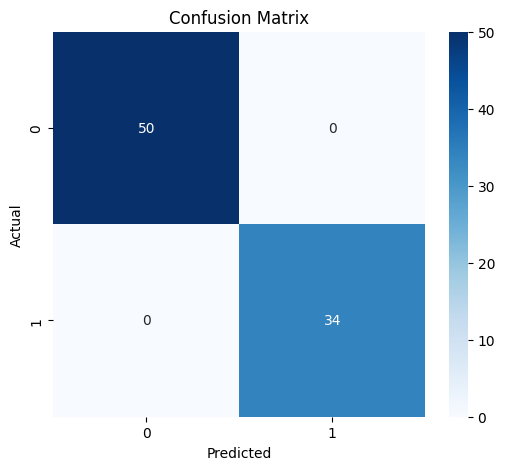

In [ ]:
plt.figure(figsize=(6,5))

sns.heatmap(cm,
            annot=True,
            fmt='d',
            cmap='Blues')

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.title("Confusion Matrix")

plt.show()

In [ ]:
print(classification_report(y_test, predictions))

In [ ]:
sample = [[1, 1, 25, 100, 1, 0]]

prediction = model.predict(sample)

if prediction[0] == 1:
    print("Passenger Survived")
else:
    print("Passenger Did Not Survive")